In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parents[0]
sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
from modules.features import HolisticLandmarksFeatureExtracter, FeatureTransformer
from modules.image_annotators import RealLifeTestAnnotator
from modules.model_factory import (SimpleModel,
                                  SimpleModelWithNoise,
                                  SimpleLSTMModel)
from modules.features.transformations import (FeatureWeights, 
                                              FeatureCentering,
                                              FeatureNormalizer,
                                              FeatureRemoveLegData)

from modules.utilities.file import load_dataset
from modules.process import train_and_validate_model

In [2]:
DATA_PATH: Path = PROJECT_ROOT / 'mp_data'
VALIDATION_DATA_PATH: Path = PROJECT_ROOT / 'mp_data_new_test'
TENSORFLOW_MODEL_PATH: Path = Path('./output_models/simple_model.keras')
NR_OF_EPOCHS: int = 50

feature_extracter = HolisticLandmarksFeatureExtracter()

feature_transformer_none = FeatureTransformer()
feature_transformer_normalized = FeatureTransformer([FeatureNormalizer()])
feature_transformer_weighted = FeatureTransformer([FeatureWeights(10.0, 10.0, 2.0, 0.5)])
feature_transformer_centered = FeatureTransformer([FeatureCentering()])
feature_transformer_all = FeatureTransformer([FeatureRemoveLegData(), FeatureNormalizer(), FeatureCentering(), FeatureWeights(10.0, 10.0, 2.0, 0.5)])

model_factory = SimpleModel()

In [3]:
_, baseline_training = train_and_validate_model(model_factory=model_factory,
                         feature_extracter=feature_extracter,
                         feature_transformer=feature_transformer_none,
                         train_dataset_path=DATA_PATH,
                         validation_dataset_path=VALIDATION_DATA_PATH,
                         nr_of_epochs=NR_OF_EPOCHS)

_, normalized_training = train_and_validate_model(model_factory=model_factory,
                         feature_extracter=feature_extracter,
                         feature_transformer=feature_transformer_normalized,
                         train_dataset_path=DATA_PATH,
                         validation_dataset_path=VALIDATION_DATA_PATH,
                         nr_of_epochs=NR_OF_EPOCHS)

_, weighted_training = train_and_validate_model(model_factory=model_factory,
                         feature_extracter=feature_extracter,
                         feature_transformer=feature_transformer_weighted,
                         train_dataset_path=DATA_PATH,
                         validation_dataset_path=VALIDATION_DATA_PATH,
                         nr_of_epochs=NR_OF_EPOCHS)

_, centered_training = train_and_validate_model(model_factory=model_factory,
                         feature_extracter=feature_extracter,
                         feature_transformer=feature_transformer_centered,
                         train_dataset_path=DATA_PATH,
                         validation_dataset_path=VALIDATION_DATA_PATH,
                         nr_of_epochs=NR_OF_EPOCHS)

_, all_transformations_training = train_and_validate_model(model_factory=model_factory,
                         feature_extracter=feature_extracter,
                         feature_transformer=feature_transformer_all,
                         train_dataset_path=DATA_PATH,
                         validation_dataset_path=VALIDATION_DATA_PATH,
                         nr_of_epochs=NR_OF_EPOCHS)


Actions: ['idle', 'poes', 'slapen', 'vogel']
Number of sequences: 120
Number of classes: 4
Input shape: (120, 30, 1659)
Input dtype: float32
NaN values: 0
Infinite values: 0
idle: 30 sequences
poes: 30 sequences
slapen: 30 sequences
vogel: 30 sequences
Epoch 1/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 3s 164ms/step - categorical_accuracy: 0.2167 - loss: 1.5655 - val_categorical_accuracy: 0.3500 - val_loss: 1.3925
Epoch 2/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - categorical_accuracy: 0.2667 - loss: 1.4472 - val_categorical_accuracy: 0.2750 - val_loss: 1.3975
Epoch 3/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - categorical_accuracy: 0.2000 - loss: 1.4313 - val_categorical_accuracy: 0.2500 - val_loss: 1.3842
Epoch 4/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - categorical_accuracy: 0.2750 - loss: 1.4301 - val_categorical_accuracy: 0.2417 - val_loss: 1.4165
Epoch 5/50
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - categorical_accuracy: 0.2333 - loss: 1.4396 - val_categorical_accuracy: 0.2583 - val_loss: 1.3620
E

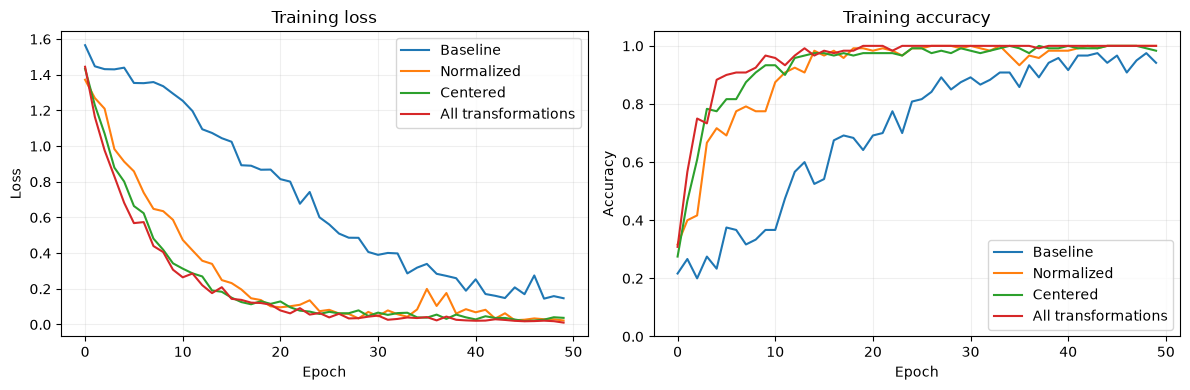

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for label, history in [("Baseline", baseline_training),
                       ("Normalized", normalized_training), 
                       ("Centered", centered_training),
                       ("All transformations", all_transformations_training)]:
    axes[0].plot(history.history["loss"], label=label)
    axes[1].plot(history.history["categorical_accuracy"], label=label)
axes[0].set(title="Training loss", xlabel="Epoch", ylabel="Loss")
axes[1].set(title="Training accuracy", xlabel="Epoch", ylabel="Accuracy", ylim=(0, 1.05))
for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()